# Análise de despesas com viagens — janeiro a junho de 2025

Execute nesta ordem: `0_criar_banco.py`, `1_extrair.py`, `2_transformar.py` e este notebook. A seleção da base corresponde ao primeiro semestre de 2025; datas finais posteriores, inclusive em 2026, são mantidas. Custo da viagem = diárias + passagens + outros gastos − devoluções; componente ausente é tratado como zero apenas nessa soma.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text
from banco import motor
sns.set_theme(style="whitegrid", palette="viridis")
engine = motor()
def consultar(sql): return pd.read_sql(text(sql), engine)
print("Conectado ao banco do projeto.")

Conectado ao banco do projeto.


## Pergunta 1 — Cinco órgãos superiores com maior custo total

,orgao,custo_total
0,Ministério da Justiça e Segurança Pública,"R$ 486,933,121.65"
1,Ministério da Defesa,"R$ 156,070,304.49"
2,Ministério da Educação,"R$ 111,291,349.34"
3,Ministério do Meio Ambiente e Mudança do Clima,"R$ 49,697,710.16"
4,Ministério da Previdência Social,"R$ 40,417,309.06"


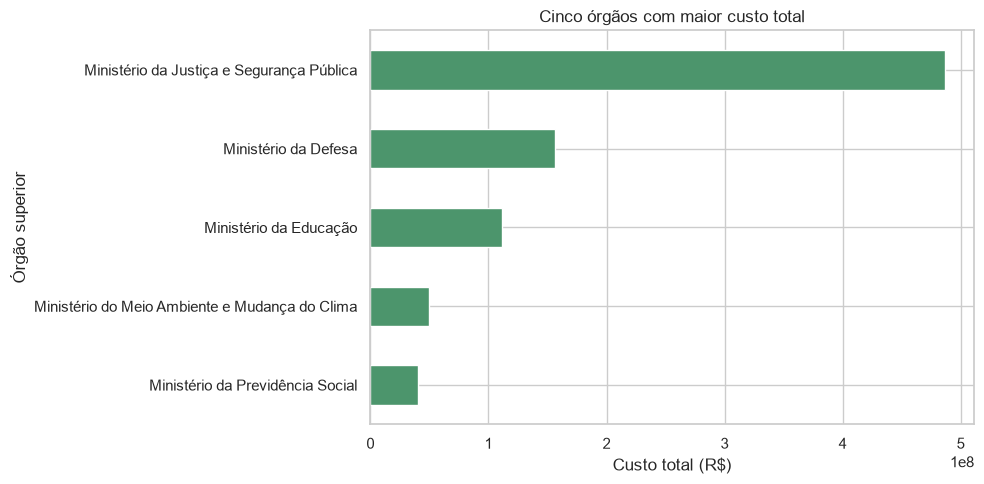

In [2]:
q1 = consultar("""SELECT nome_orgao_superior AS orgao, SUM(valor_total) AS custo_total
FROM silver_viagem GROUP BY nome_orgao_superior ORDER BY custo_total DESC LIMIT 5""")
display(q1.style.format({"custo_total": "R$ {:,.2f}"}))
ax=q1.sort_values("custo_total").plot.barh(x="orgao",y="custo_total",legend=False,figsize=(10,5),color="#4c956c")
ax.set(title="Cinco órgãos com maior custo total",xlabel="Custo total (R$)",ylabel="Órgão superior")
plt.tight_layout(); plt.show()

## Pergunta 2 — Três destinos com maior custo médio por viagem
Agrupa pelo texto completo do campo Destinos, evitando duplicar custo por causa de vários trechos.

,destino,viagens,custo_medio
0,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ",1,"R$ 245,852.80"
1,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, Rio Branco/AC, Brasília/DF, São Paulo/SP, Brasília/DF, Cuiabá/MT, Brasília/DF, Teresina/PI, Brasília/DF, Maceió/AL, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Palmas/TO, Brasília/DF, Manaus/AM, Brasília/DF, Cuiabá/MT, Brasília/DF, Campinas/SP, Brasília/DF, Belo Horizonte/MG, Porto Alegre/RS, Brasília/DF, Foz do Iguaçu/PR, Brasília/DF, Fortaleza/CE, Brasília/DF, Belém/PA, Manaus/AM, Brasília/DF, Curitiba/PR, Foz do Iguaçu/PR, Brasília/DF, Fortaleza/CE, Brasília/DF, São Paulo/SP, Brasília/DF, Salvador/BA, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Natal/RN, João Pessoa/PB, Brasília/DF, Brasília/DF",1,"R$ 216,729.36"
2,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, Rio de Janeiro/RJ, Brasília/DF, Belém/PA, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Belém/PA, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Cuiabá/MT, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Palmas/TO, Brasília/DF, Florianópolis/SC, Brasília/DF, Belo Horizonte/MG, Brasília/DF, Belém/PA, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Belém/PA, Brasília/DF",1,"R$ 207,220.14"


C:\Users\Ednelson\AppData\Local\Temp\ipykernel_22440\2847484328.py:6: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


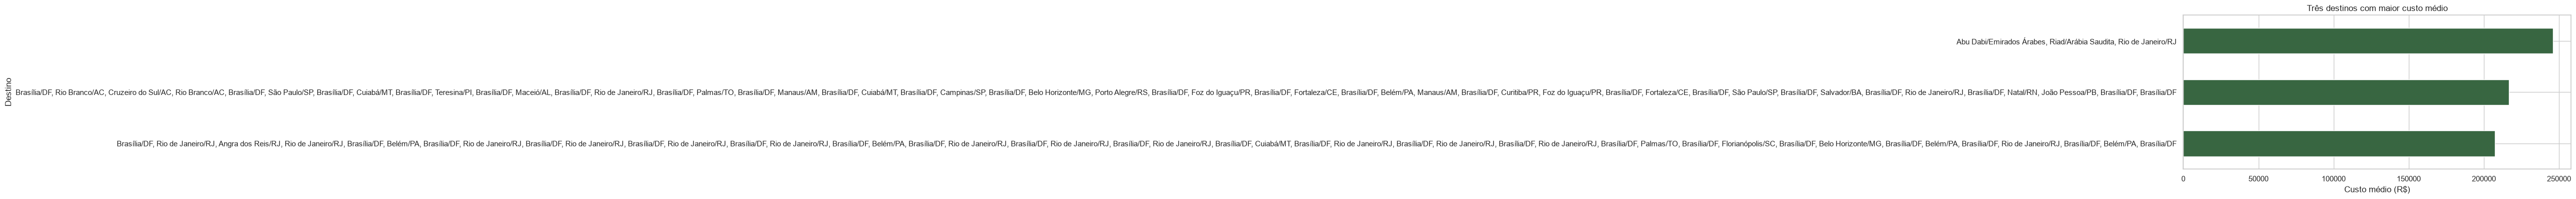

In [3]:
q2 = consultar("""SELECT destinos AS destino, COUNT(*) AS viagens, AVG(valor_total) AS custo_medio
FROM silver_viagem WHERE destinos IS NOT NULL GROUP BY destinos ORDER BY custo_medio DESC LIMIT 3""")
display(q2.style.format({"custo_medio": "R$ {:,.2f}"}))
ax=q2.sort_values("custo_medio").plot.barh(x="destino",y="custo_medio",legend=False,figsize=(10,4),color="#386641")
ax.set(title="Três destinos com maior custo médio",xlabel="Custo médio (R$)",ylabel="Destino")
plt.tight_layout(); plt.show()

## Pergunta 3 — Viagem mais longa e seu custo

,id_viagem,nome_viajante,nome_orgao_superior,destinos,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,Ministério da Previdência Social,Mogi Mirim/SP,2025-01-13,2026-01-31,383,R$ 0.00


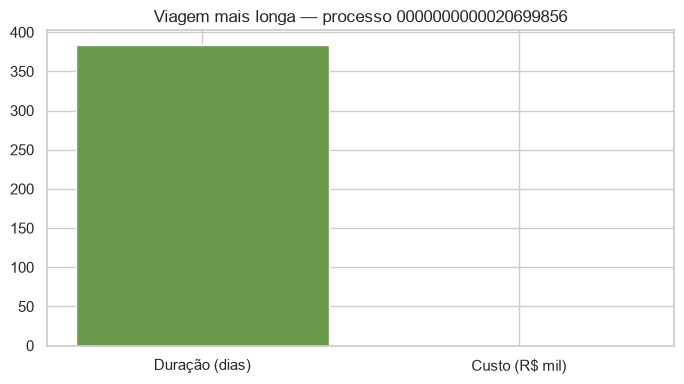

In [4]:
q3 = consultar("""SELECT id_viagem,nome_viajante,nome_orgao_superior,destinos,data_inicio,data_fim,duracao_dias,valor_total
FROM silver_viagem WHERE duracao_dias IS NOT NULL ORDER BY duracao_dias DESC,valor_total DESC LIMIT 1""")
display(q3.style.format({"valor_total": "R$ {:,.2f}"}))
if not q3.empty:
    x=q3.iloc[0]
    plt.figure(figsize=(7,4)); plt.bar(["Duração (dias)","Custo (R$ mil)"],[x.duracao_dias,x.valor_total/1000],color=["#6a994e","#a7c957"])
    plt.title(f"Viagem mais longa — processo {x.id_viagem}"); plt.tight_layout(); plt.show()

## Camada Gold
Agrega as tabelas filhas antes das junções para impedir multiplicação de valores. Recria apenas os objetos Gold.

In [5]:
gold_sql = """
DROP VIEW IF EXISTS gold_resumo_viagem_vw;
DROP TABLE IF EXISTS gold_resumo_viagem;
CREATE TABLE gold_resumo_viagem AS
WITH pagamentos AS (SELECT id_viagem,SUM(valor) valor_pago,COUNT(*) quantidade_pagamentos FROM silver_pagamento GROUP BY id_viagem),
passagens AS (SELECT id_viagem,SUM(COALESCE(valor_passagem,0)+COALESCE(taxa_servico,0)) custo_passagens FROM silver_passagem GROUP BY id_viagem),
trechos AS (SELECT id_viagem,COUNT(*) quantidade_trechos FROM silver_trecho GROUP BY id_viagem)
SELECT v.id_viagem,v.nome_orgao_superior,v.valor_total,v.duracao_dias,
 COALESCE(p.valor_pago,0) valor_pago,COALESCE(p.quantidade_pagamentos,0) quantidade_pagamentos,
 COALESCE(a.custo_passagens,0) custo_passagens,COALESCE(t.quantidade_trechos,0) quantidade_trechos
FROM silver_viagem v LEFT JOIN pagamentos p USING(id_viagem)
LEFT JOIN passagens a USING(id_viagem) LEFT JOIN trechos t USING(id_viagem);
CREATE VIEW gold_resumo_viagem_vw AS SELECT * FROM gold_resumo_viagem;"""
with engine.begin() as conn:
    for statement in gold_sql.split(";"):
        if statement.strip(): conn.execute(text(statement))
print("Tabela e view Gold criadas.")

Tabela e view Gold criadas.


## Pergunta 4 — Tipo de pagamento com maior valor médio

,tipo_pagamento,pagamentos,valor_medio
0,DIÁRIAS,401463,"R$ 2,078.28"
1,PASSAGEM,188985,"R$ 1,878.34"
2,Serviço correlato: seguro,4894,R$ 447.51
3,RESTITUIÇÃO,11574,R$ 245.70


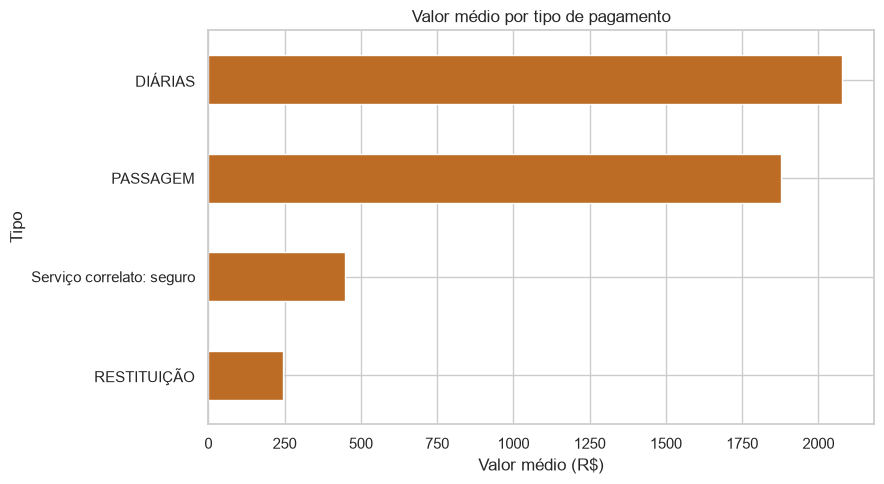

In [6]:
q4=consultar("""SELECT tipo_pagamento,COUNT(*) pagamentos,AVG(valor) valor_medio FROM silver_pagamento
GROUP BY tipo_pagamento ORDER BY valor_medio DESC""")
display(q4.style.format({"valor_medio":"R$ {:,.2f}"}))
ax=q4.sort_values("valor_medio").plot.barh(x="tipo_pagamento",y="valor_medio",legend=False,figsize=(9,5),color="#bc6c25")
ax.set(title="Valor médio por tipo de pagamento",xlabel="Valor médio (R$)",ylabel="Tipo"); plt.tight_layout(); plt.show()

## Perguntas 5 e 6 — Meio de transporte mais usado e UF de destino mais frequente

,meio_transporte,trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


,uf_destino,ocorrencias
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


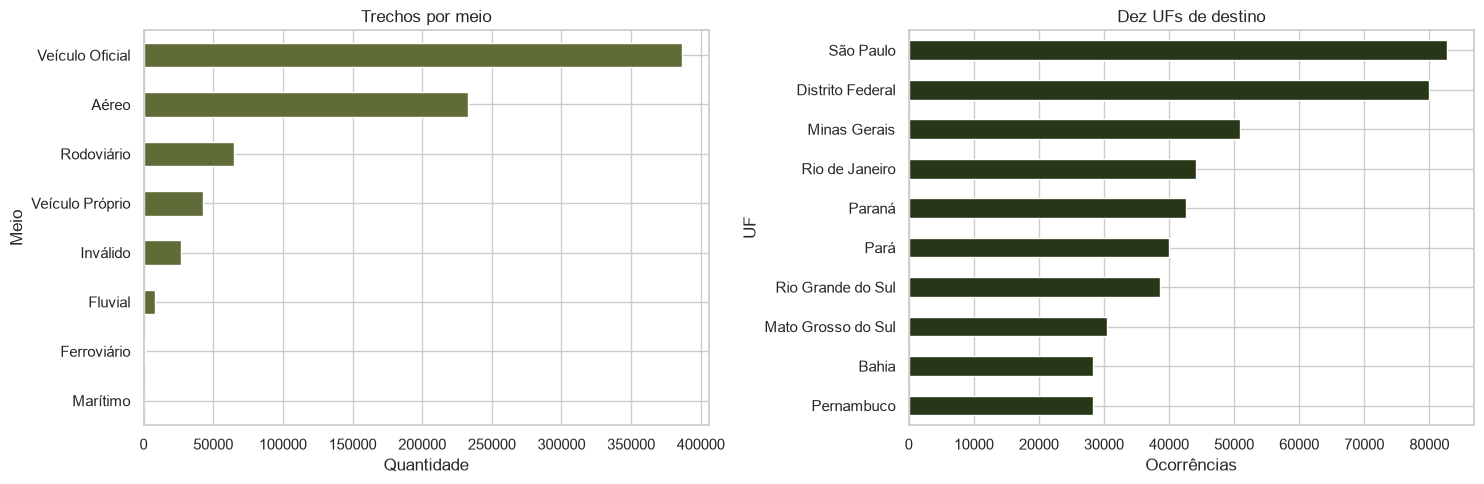

In [7]:
q5=consultar("""SELECT meio_transporte,COUNT(*) trechos FROM silver_trecho WHERE meio_transporte IS NOT NULL
GROUP BY meio_transporte ORDER BY trechos DESC""")
q6=consultar("""SELECT destino_uf uf_destino,COUNT(*) ocorrencias FROM silver_trecho WHERE destino_uf IS NOT NULL
GROUP BY destino_uf ORDER BY ocorrencias DESC LIMIT 10""")
display(q5); display(q6)
fig,ax=plt.subplots(1,2,figsize=(15,5))
q5.head(8).sort_values("trechos").plot.barh(x="meio_transporte",y="trechos",ax=ax[0],legend=False,color="#606c38")
q6.sort_values("ocorrencias").plot.barh(x="uf_destino",y="ocorrencias",ax=ax[1],legend=False,color="#283618")
ax[0].set(title="Trechos por meio",xlabel="Quantidade",ylabel="Meio"); ax[1].set(title="Dez UFs de destino",xlabel="Ocorrências",ylabel="UF")
plt.tight_layout(); plt.show()

## Pergunta 7 — Órgão pagador com maior valor total

,orgao_pagador,total_pago,pagamentos
0,Fundo Nacional de Segurança Pública,"R$ 278,481,047.89",79816
1,Sigiloso,"R$ 200,484,801.68",93141
2,Comando da Aeronáutica,"R$ 81,769,144.77",46193
3,Instituto Nacional do Seguro Social,"R$ 37,427,601.45",18324
4,Comando do Exército,"R$ 36,872,643.95",22837
5,Ministério da Gestão e da Inovação em Serviços Públicos - Unidades com vínculo direto,"R$ 35,541,760.71",20291
6,Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis,"R$ 31,589,853.15",16758
7,Ministério das Relações Exteriores - Unidades com vínculo direto,"R$ 25,605,376.38",3705
8,Receita Federal do Brasil,"R$ 23,811,027.00",18917
9,Ministério da Agricultura e Pecuária - Unidades com vínculo direto,"R$ 22,899,880.25",15864


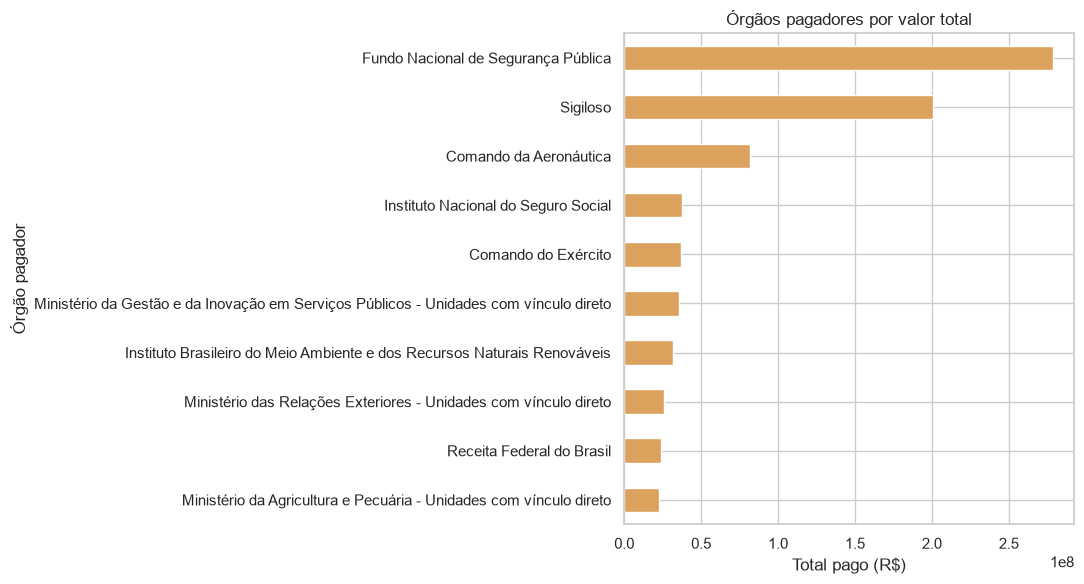

In [8]:
q7=consultar("""SELECT p.nome_orgao_pagador orgao_pagador,SUM(p.valor) total_pago,COUNT(*) pagamentos
FROM silver_pagamento p JOIN gold_resumo_viagem_vw g USING(id_viagem)
WHERE p.nome_orgao_pagador IS NOT NULL GROUP BY p.nome_orgao_pagador ORDER BY total_pago DESC LIMIT 10""")
display(q7.style.format({"total_pago":"R$ {:,.2f}"}))
ax=q7.sort_values("total_pago").plot.barh(x="orgao_pagador",y="total_pago",legend=False,figsize=(11,6),color="#dda15e")
ax.set(title="Órgãos pagadores por valor total",xlabel="Total pago (R$)",ylabel="Órgão pagador"); plt.tight_layout(); plt.show()

## Observações sobre os dados
- Campos como cargo, CPF, UF e data de emissão podem estar vazios na fonte; não são preenchidos artificialmente.
- A categoria de transporte `Inválido` existe na fonte e é mantida nas contagens.
- A base inclui viagens iniciadas no primeiro semestre, com datas finais que podem avançar para 2026.
- Q2 agrupa o texto integral de Destinos; grafias diferentes podem aparecer como destinos separados.